In [189]:
from statistics import linear_regression

import pandas as pd
import numpy as np
from scipy import stats
from sklearn.metrics import mean_squared_error

import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split , GridSearchCV, cross_val_score
from sklearn.compose import make_column_transformer , ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder , OrdinalEncoder

from sklearn.linear_model import LinearRegression ,Ridge, Lasso , ElasticNet
from sklearn.ensemble import RandomForestRegressor
from torch.backends.opt_einsum import strategy
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.kernel_ridge import KernelRidge


In [190]:
def plot_numeric_vs_saleprice(df):
    """
    Plots scatter plots of all numerical features against the target variable 'SalePrice'.

    This function iterates through all numerical columns in the given DataFrame (excluding 
    object-type columns and the 'SalePrice' column itself), and creates a scatter plot 
    between each feature and 'SalePrice'. It is useful for visually analyzing the 
    relationships and possible correlations between features and the target variable.

    Parameters
    ----------
    df : pandas.DataFrame
        A dataset that includes numerical features and the target column 'SalePrice'.

    Returns
    -------
    None
        The function does not return anything. It displays the plots using matplotlib.
    """
    numeric_cols = df.dtypes[df.dtypes != 'object'].index
    numeric_cols = [col for col in numeric_cols if col != 'SalePrice']  # exclude target

    for col in numeric_cols:
        plt.figure(figsize=(6, 4))
        sns.scatterplot(x=col, y='SalePrice', data=df)
        plt.title(f'{col} vs SalePrice')
        plt.xlabel(col)
        plt.ylabel('SalePrice')
        plt.tight_layout()
        plt.show()


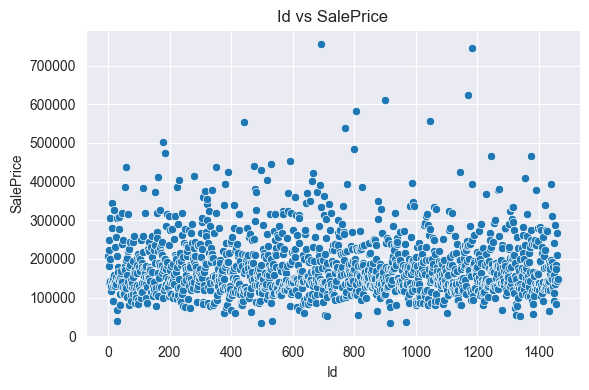

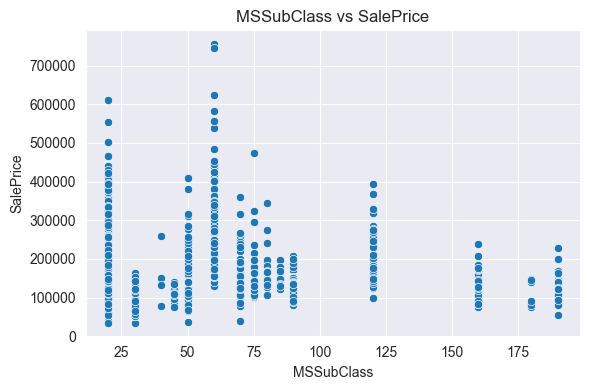

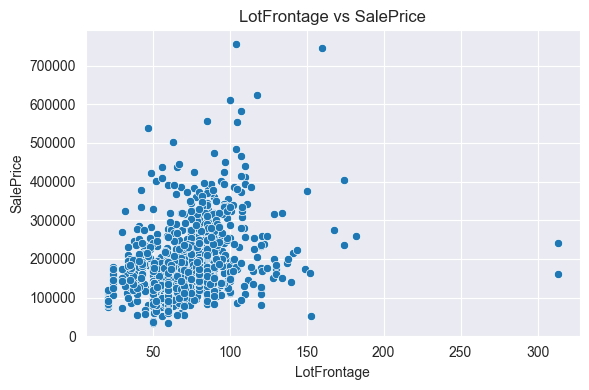

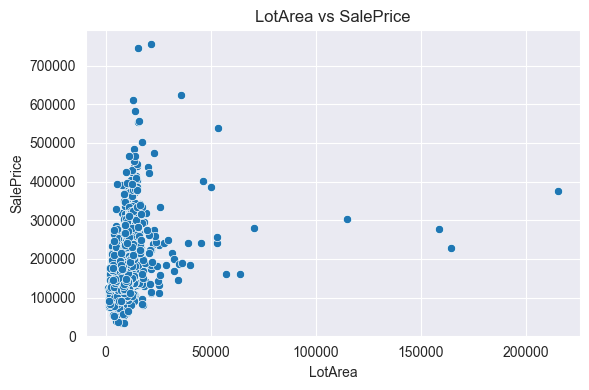

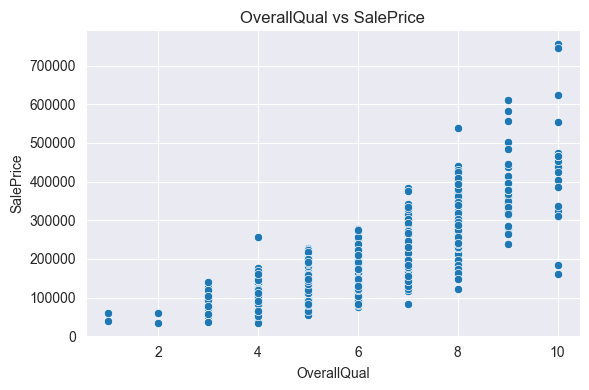

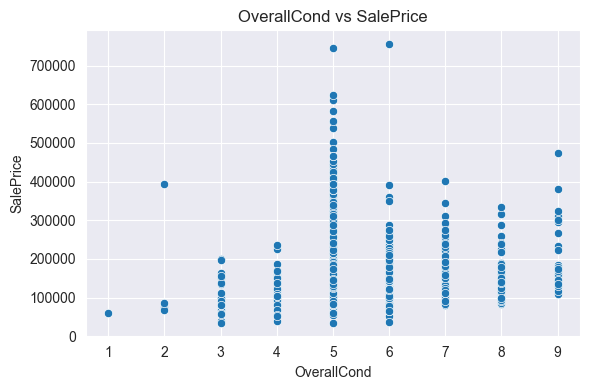

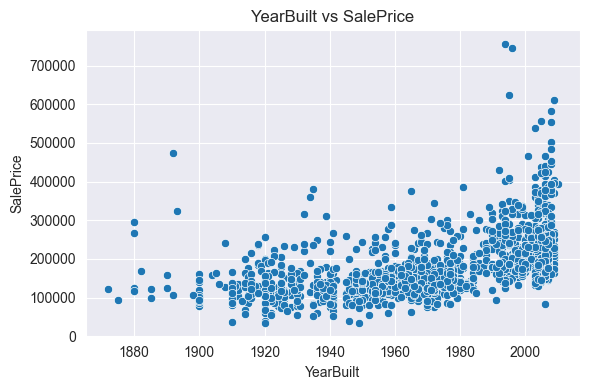

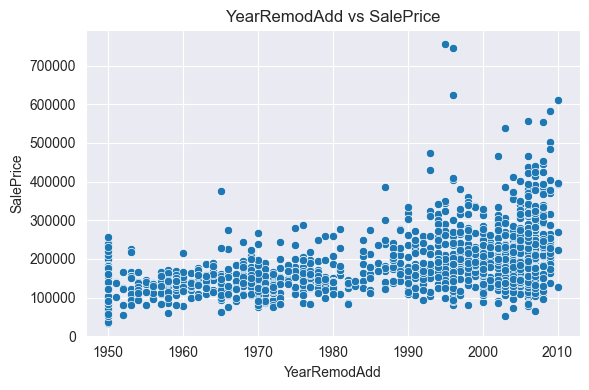

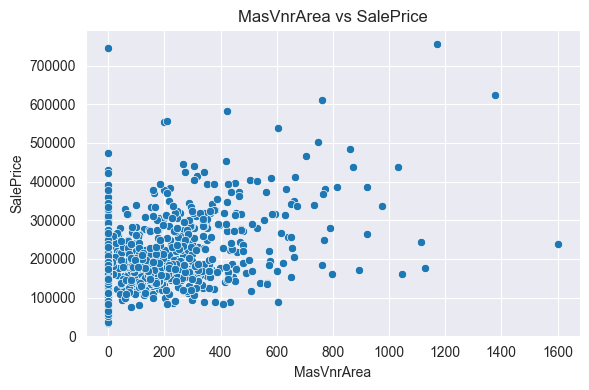

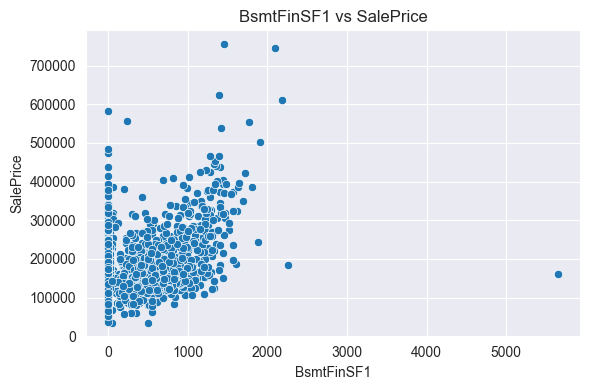

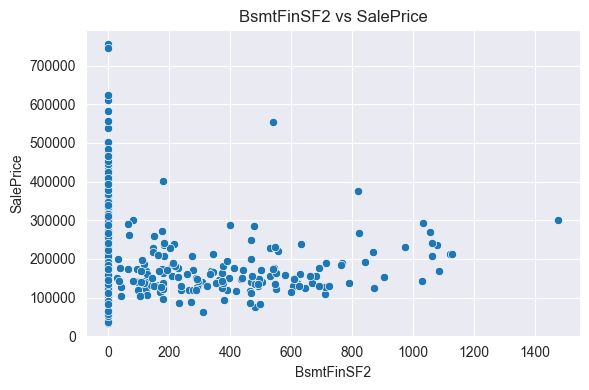

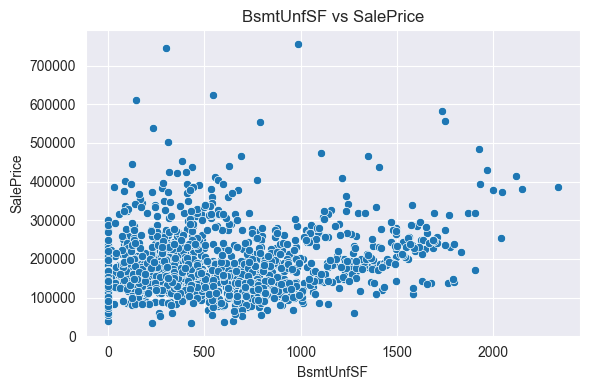

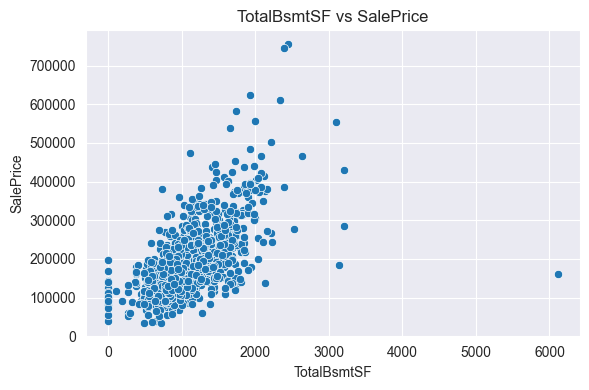

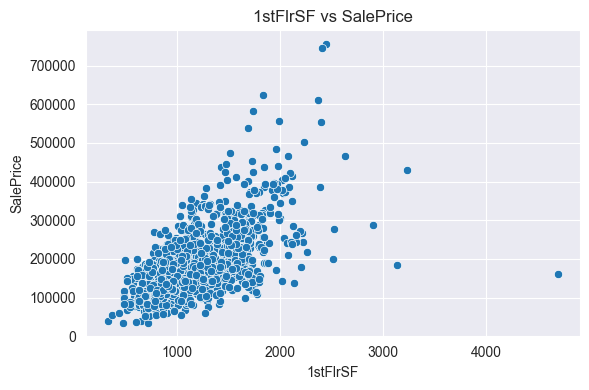

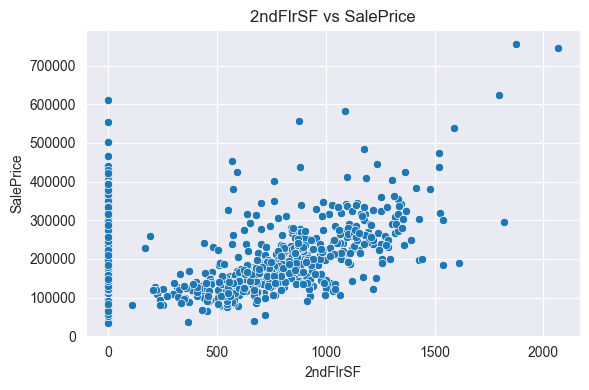

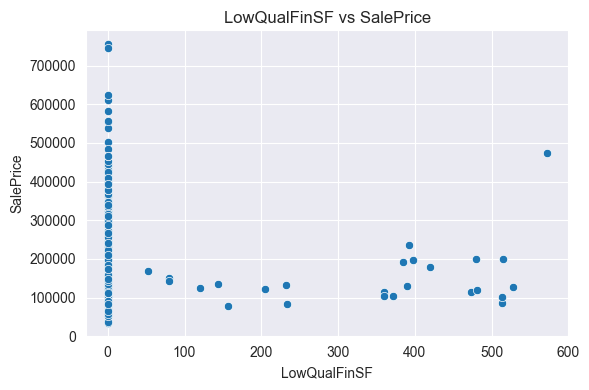

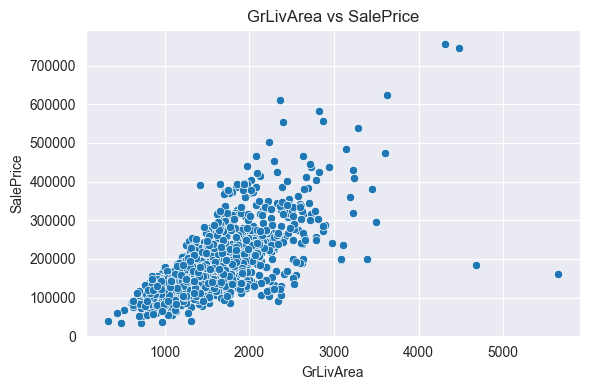

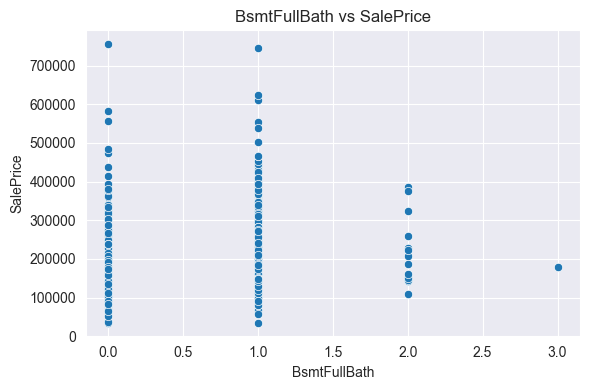

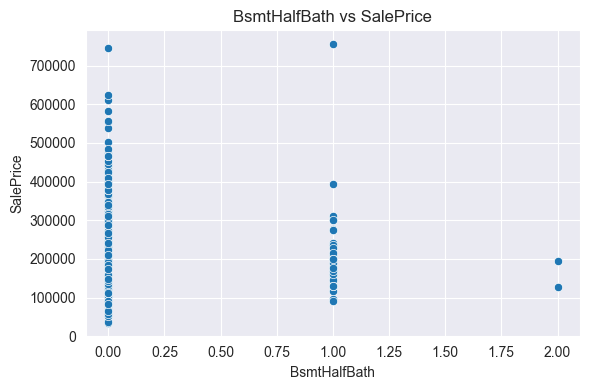

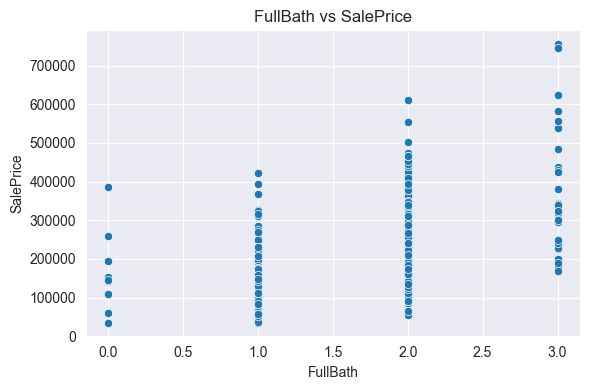

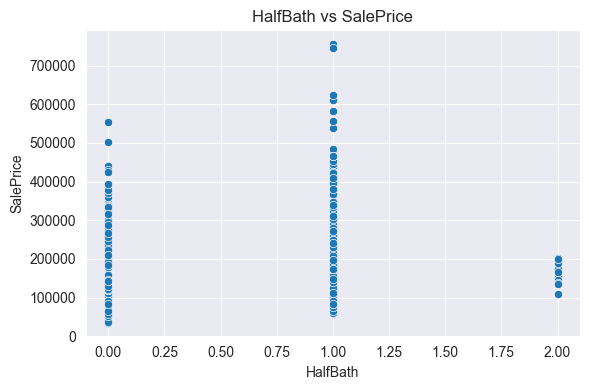

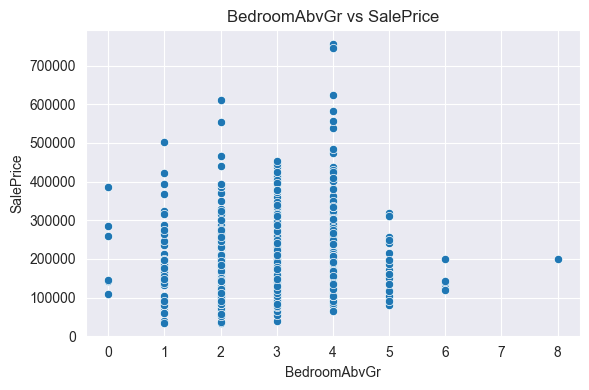

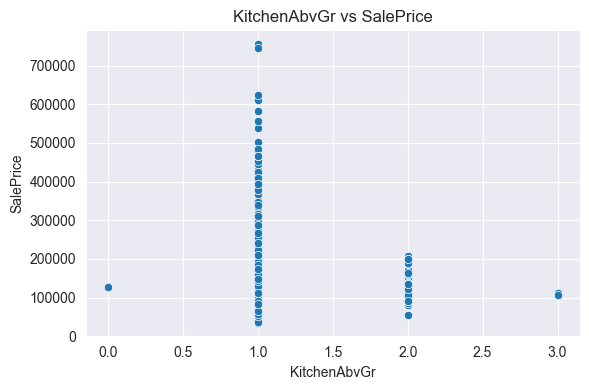

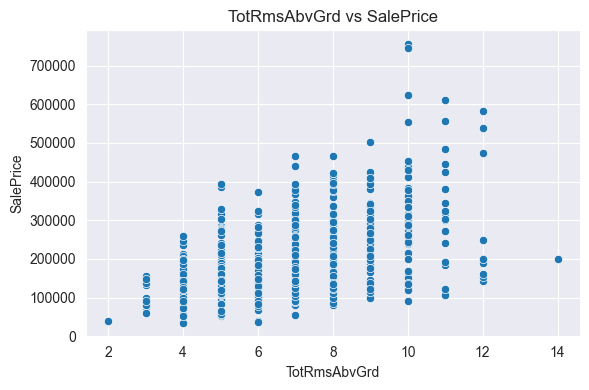

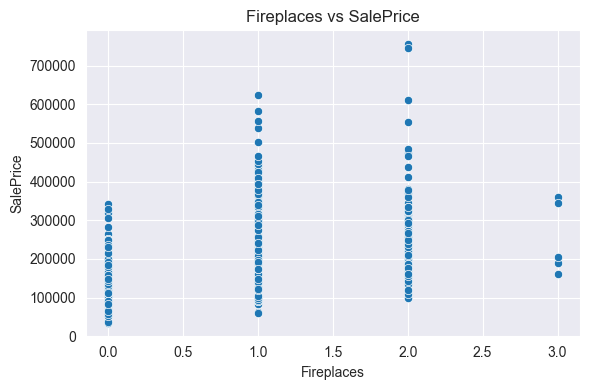

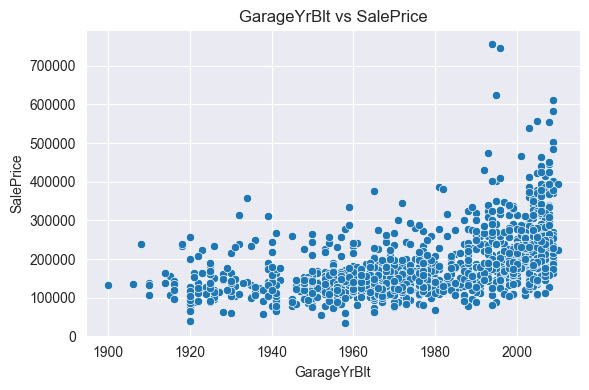

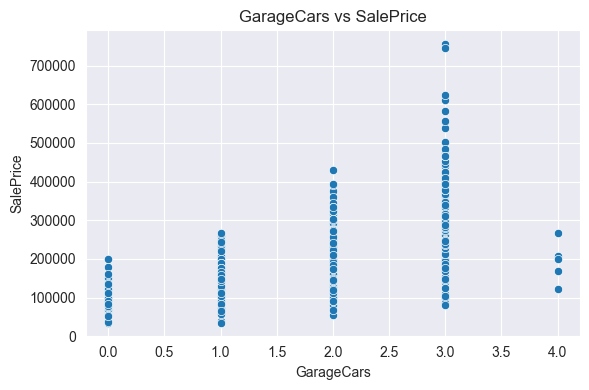

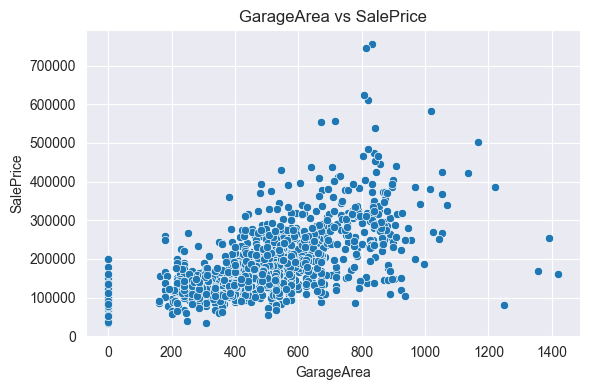

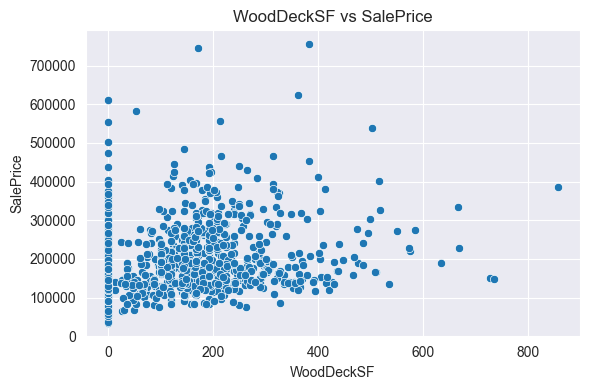

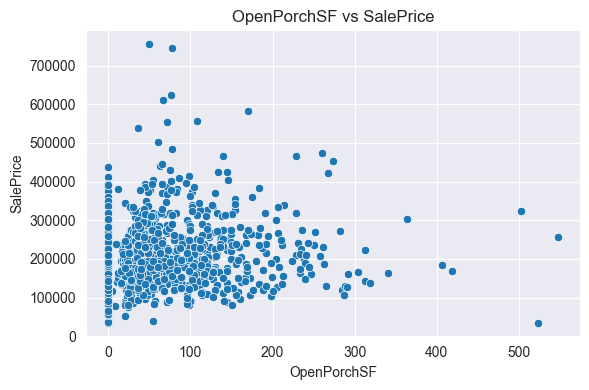

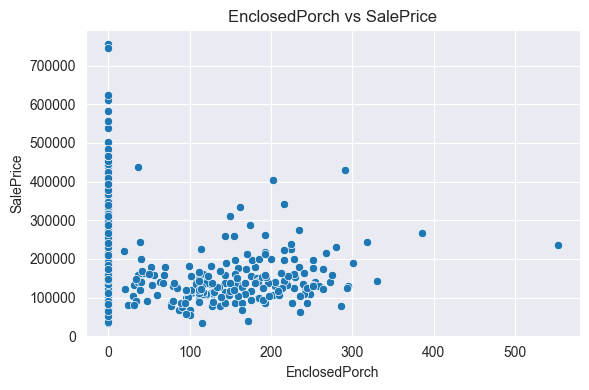

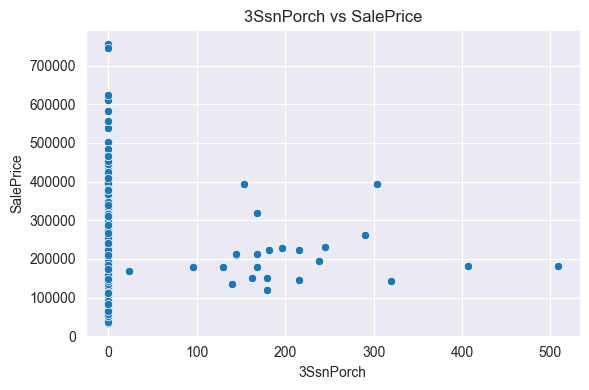

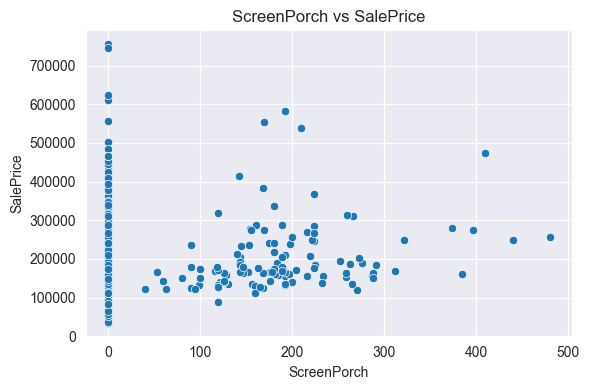

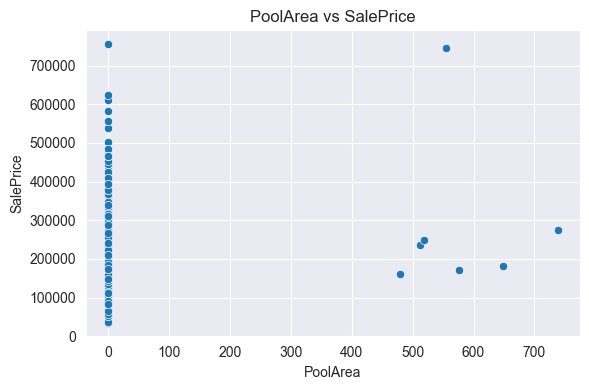

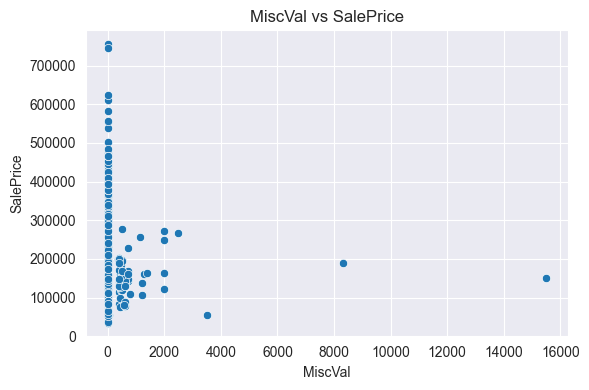

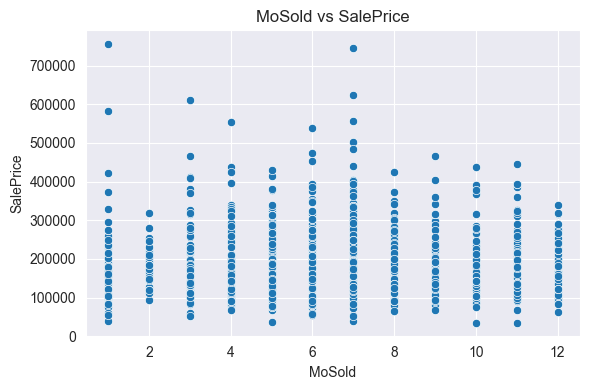

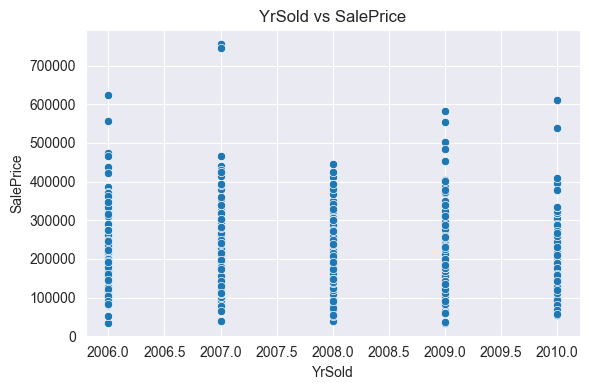

In [61]:
plot_numeric_vs_saleprice(df_train.select_dtypes(exclude=['object']))

In [193]:
df_train = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')

In [63]:
df_train.query('YearBuilt < 1990 & SalePrice >400000')
#Drop 186

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
185,186,75,RM,90.0,22950,Pave,NaN,IR2,Lvl,AllPub,...,0,NaN,GdPrv,NaN,0,6,2006,WD,Normal,475000


In [195]:
df_train.query('OverallCond > 2 & SalePrice > 700000')
#drop 379 , 1183

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
691,692,60,RL,104.0,21535,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2007,WD,Normal,755000
1182,1183,60,RL,160.0,15623,Pave,NaN,IR1,Lvl,AllPub,...,555,Ex,MnPrv,NaN,0,7,2007,WD,Abnorml,745000


In [196]:
df_train.query('YearBuilt> 1980 & SalePrice > 600000')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
691,692,60,RL,104.0,21535,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2007,WD,Normal,755000
898,899,20,RL,100.0,12919,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,3,2010,New,Partial,611657
1169,1170,60,RL,118.0,35760,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,WD,Normal,625000
1182,1183,60,RL,160.0,15623,Pave,NaN,IR1,Lvl,AllPub,...,555,Ex,MnPrv,NaN,0,7,2007,WD,Abnorml,745000


In [197]:
df_train.query('YearRemodAdd < 1970 & SalePrice > 300000')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
313,314,20,RL,150.0,215245,Pave,NaN,IR3,Low,AllPub,...,0,NaN,NaN,NaN,0,6,2009,WD,Normal,375000


In [198]:
df_train.query('MasVnrArea > 1500')
#drop 298

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
297,298,60,FV,66.0,7399,Pave,Pave,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2007,WD,Normal,239000


In [199]:
df_train.query('BsmtFinSF2 > 400 & SalePrice > 500000')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
440,441,20,RL,105.0,15431,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2009,WD,Normal,555000


In [200]:
df_train = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')

In [201]:
values = [598, 955, 935, 1299, 250, 314, 336, 707, 379, 1183, 692, 186, 441, 186, 524, 739, 598, 955, 636, 1062, 1191, 496, 198, 1338]

df_train = df_train[~df_train.Id.isin(values)]


In [202]:
pd.DataFrame(df_train.isnull().sum().sort_values(ascending = False)).head(20)

,0
PoolQC,1435
MiscFeature,1388
Alley,1350
Fence,1162
MasVnrType,861
FireplaceQu,684
LotFrontage,255
GarageYrBlt,76
GarageCond,76
GarageType,76


In [203]:

df_train['MiscFeature'].unique()

array([nan, 'Shed', 'Gar2', 'Othr', 'TenC'], dtype=object)

In [204]:
df_train['Alley'].unique()

array([nan, 'Grvl', 'Pave'], dtype=object)

In [205]:
df_train['Alley'] = df_train['Alley'].fillna('No')
df_test['Alley'] = df_test['Alley'].fillna('No')


In [206]:
df_train['Alley'].isnull().sum()

np.int64(0)

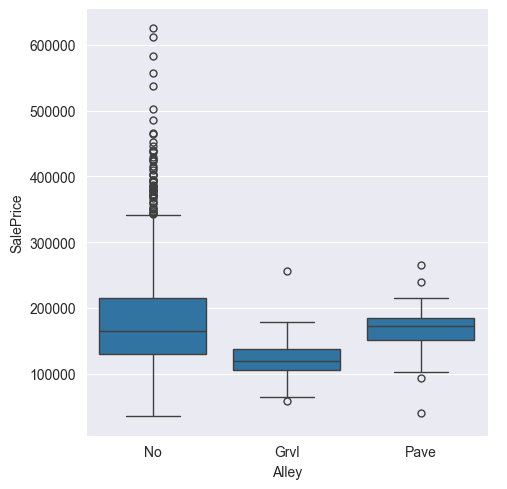

In [207]:
sns.catplot(data = df_train, x = 'Alley', y = 'SalePrice',kind = 'box')

In [208]:
df_train.query('Alley == "Pave"').count()

Id               40
MSSubClass       40
MSZoning         40
LotFrontage      38
LotArea          40
                 ..
MoSold           40
YrSold           40
SaleType         40
SaleCondition    40
SalePrice        40
Length: 81, dtype: int64

In [209]:
df_train['Fence'].unique()

array([nan, 'MnPrv', 'GdWo', 'GdPrv', 'MnWw'], dtype=object)

In [210]:
df_train['Fence'] = df_train['Fence'].fillna('No')
df_test['Fence'] = df_test['Fence'].fillna('No')

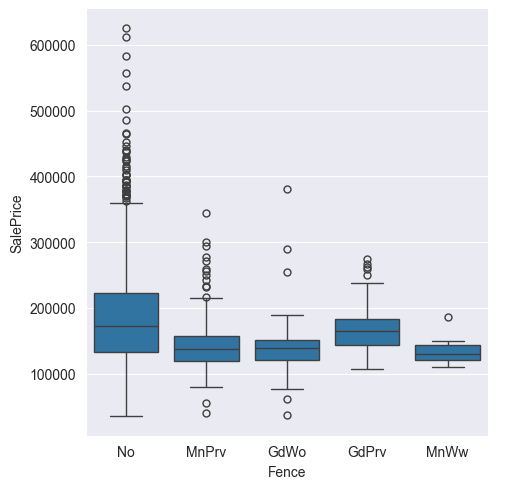

In [79]:
sns.catplot(df_train , x = 'Fence', y = 'SalePrice',kind = 'box')

In [80]:
df_train['MasVnrArea'].isnull().sum()
df_test['MasvnrArea'] = df_test['MasVnrArea'].fillna('0')
df_train['MasvnrArea'] = df_test['MasVnrArea'].fillna('0')


In [81]:
df_train['FireplaceQu'].unique()

array([nan, 'TA', 'Gd', 'Fa', 'Ex', 'Po'], dtype=object)

In [82]:
df_train['FireplaceQu'] = df_train['FireplaceQu'].fillna('No')
df_test['FireplaceQu'] = df_test['FireplaceQu'].fillna('No')

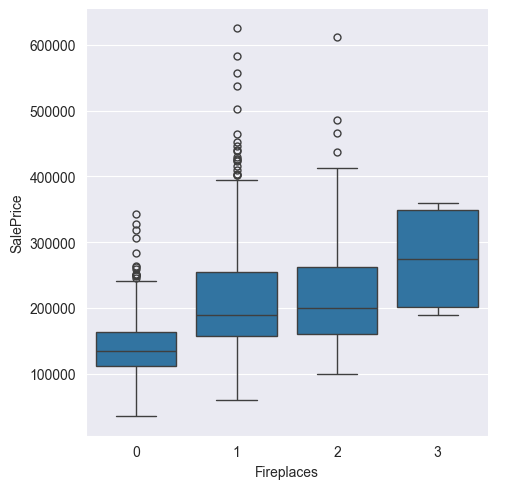

In [83]:
sns.catplot(df_train , x = 'Fireplaces', y = 'SalePrice',kind = 'box')

In [84]:
df_train['LotFrontage'].isnull().sum()

df_train['LotFrontage'] = df_train['LotFrontage'].fillna(0)
df_test['LotFrontage'] = df_test['LotFrontage'].fillna(0)

In [85]:
df_train.isnull().sum()

Id               0
MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
                ..
YrSold           0
SaleType         0
SaleCondition    0
SalePrice        0
MasvnrArea       1
Length: 82, dtype: int64

In [86]:
df_train['GarageYrBlt'].corr(df_train['YearBuilt'])

np.float64(0.8289827595060576)

In [87]:
df_train['GarageCond'].unique()
df_train['GarageCond'] = df_train['GarageCond'].fillna('No')
df_test['GarageCond'] = df_test['GarageCond'].fillna('No')


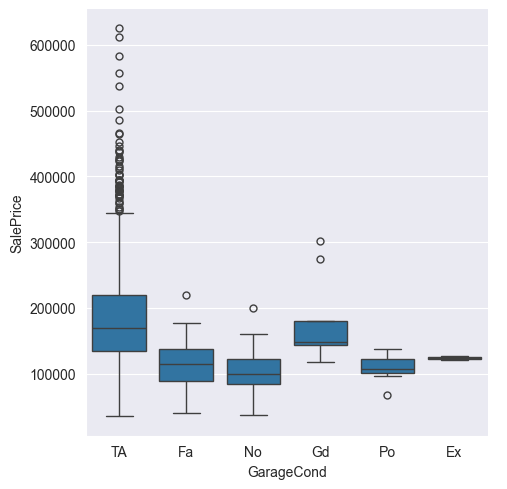

In [88]:
sns.catplot(df_train, x = 'GarageCond', y = 'SalePrice',kind = 'box')

In [89]:
df_train['GarageType'].unique()
df_train['GarageType'] = df_train['GarageType'].fillna('No')
df_test['GarageType'] = df_test['GarageType'].fillna('No')

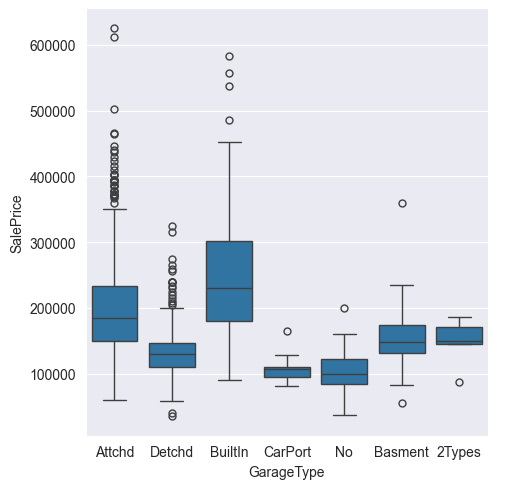

In [90]:
sns.catplot(df_train, x = 'GarageType', y = 'SalePrice',kind = 'box')

In [91]:
df_train['GarageFinish'].unique()
df_train['GarageFinish'] = df_train['GarageFinish'].fillna('No')
df_test['GarageFinish'] = df_test['GarageFinish'].fillna('No')


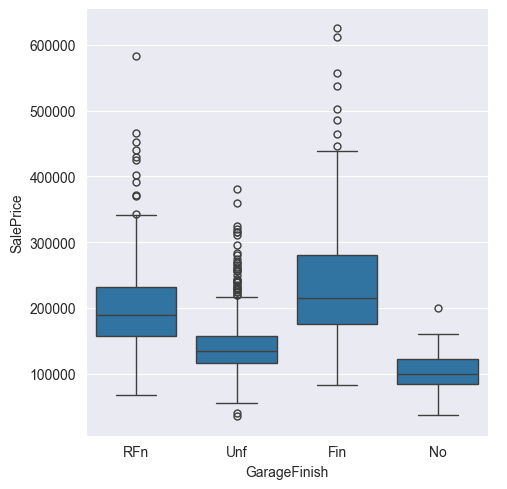

In [92]:
sns.catplot(df_train, x = 'GarageFinish', y = 'SalePrice',kind = 'box')

In [93]:
#df_train['BsmtFinType2'] = df_train['BsmtFinType2'].fillna('Unf')
#df_test['BsmtFinType2'] = df_test['BsmtFinType2'].fillna('Unf')

df_train['BsmtFinType2'].unique()

array(['Unf', 'BLQ', nan, 'ALQ', 'Rec', 'LwQ', 'GLQ'], dtype=object)

In [94]:
numeric_cols = df_train.dtypes[df_train.dtypes != 'object'].index
for col in numeric_cols:
    print(f'{col}')


Id
MSSubClass
LotFrontage
LotArea
OverallQual
OverallCond
YearBuilt
YearRemodAdd
MasVnrArea
BsmtFinSF1
BsmtFinSF2
BsmtUnfSF
TotalBsmtSF
1stFlrSF
2ndFlrSF
LowQualFinSF
GrLivArea
BsmtFullBath
BsmtHalfBath
FullBath
HalfBath
BedroomAbvGr
KitchenAbvGr
TotRmsAbvGrd
Fireplaces
GarageYrBlt
GarageCars
GarageArea
WoodDeckSF
OpenPorchSF
EnclosedPorch
3SsnPorch
ScreenPorch
PoolArea
MiscVal
MoSold
YrSold
SalePrice


In [95]:
#df_train['BsmtExposure'].unique()
df_train['BsmtExposure'] = df_train['BsmtExposure'].fillna('No')
df_test['BsmtExposure'] = df_test['BsmtExposure'].fillna('No')

In [96]:
#df_train['BsmtQual'].unique()
df_train['BsmtQual'] = df_train['BsmtQual'].fillna('No')
df_test['BsmtQual'] = df_test['BsmtQual'].fillna('No')

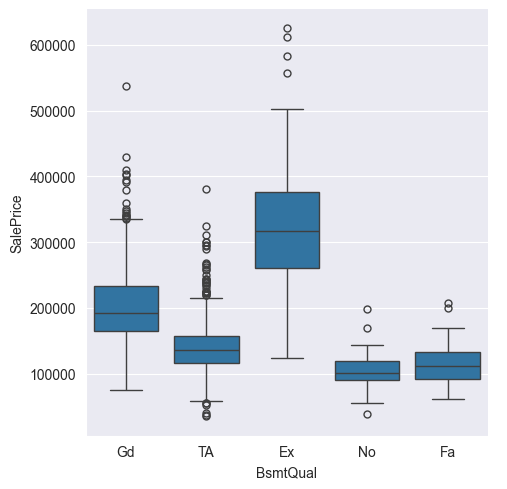

In [97]:
sns.catplot(df_train , x = 'BsmtQual', y = 'SalePrice',kind = 'box')

In [98]:
#df_train['BsmtFinType1'].unique()
df_train['BsmtFinType1'] = df_train['BsmtFinType1'].fillna('Unf')
df_test['BsmtFinType1'] = df_test['BsmtFinType1'].fillna('Unf')


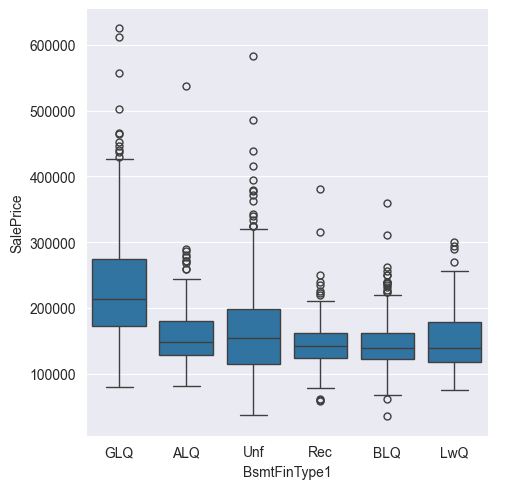

In [99]:
sns.catplot(df_train, x = 'BsmtFinType1', y = 'SalePrice',kind = 'box')

In [100]:
df_train['MasvnrArea'] = df_train['MasVnrArea'].fillna(0)
df_test['MasvnrArea'] = df_test['MasVnrArea'].fillna(0)
df_train['Electrical'] = df_train['Electrical'].fillna('SBrkr')
df_test['Electrical'] = df_test['Electrical'].fillna('SBrkr')


In [101]:
df_train = df_train.drop(columns=['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'GarageYrBlt', 'GarageCond', 'BsmtFinType2'])
df_test = df_test.drop(columns=['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'GarageYrBlt', 'GarageCond', 'BsmtFinType2'])

## Lots of empty

# Feature Engineering


In [211]:
df_train['house_age'] = df_train['YrSold'] - df_train['YearBuilt']
df_test['house_age'] = df_test['YrSold'] - df_test['YearBuilt']


In [212]:
df_train['house_remodel_age'] = df_train['YrSold'] - df_train['YearRemodAdd']
df_train['totalsf'] = df_train['1stFlrSF'] + df_train['2ndFlrSF'] + df_train['BsmtFinSF1']+ df_train['BsmtFinSF2']
df_train['totalarea'] = df_train['GrLivArea'] + df_train['TotalBsmtSF']
df_train['totalbaths'] = df_train['BsmtFullBath'] + df_train['FullBath'] + 0.5*(df_train['BsmtHalfBath'] + df_train['HalfBath'])
df_train['totalporchsf'] = df_train['OpenPorchSF'] + df_train['3SsnPorch'] + df_train['EnclosedPorch'] + df_train['ScreenPorch'] + df_train['WoodDeckSF']

df_test['house_remodel_age'] = df_test['YrSold'] - df_test['YearRemodAdd']
df_test['totalsf'] = df_test['1stFlrSF'] + df_test['2ndFlrSF'] + df_test['BsmtFinSF1'] + df_test['BsmtFinSF2']
df_test['totalarea'] = df_test['GrLivArea'] + df_test['TotalBsmtSF']
df_test['totalbaths'] = df_test['BsmtFullBath'] + df_test['FullBath'] + 0.5 * (df_test['BsmtHalfBath'] + df_test['HalfBath'])
df_test['totalporchsf'] = df_test['OpenPorchSF'] + df_test['3SsnPorch'] + df_test['EnclosedPorch'] + df_test['ScreenPorch'] + df_test['WoodDeckSF']




In [213]:
df_train = df_train.drop(columns=['Id','YrSold', 'YearBuilt', 'YearRemodAdd', '1stFlrSF', '2ndFlrSF', 'BsmtFinSF1', 'BsmtFinSF2', 'GrLivArea', 'TotalBsmtSF','BsmtFullBath', 'FullBath', 'BsmtHalfBath', 'HalfBath', 'OpenPorchSF', '3SsnPorch', 'EnclosedPorch', 'ScreenPorch','WoodDeckSF'])

df_test = df_test.drop(columns= ['Id','YrSold', 'YearBuilt', 'YearRemodAdd', '1stFlrSF', '2ndFlrSF', 'BsmtFinSF1', 'BsmtFinSF2', 'GrLivArea', 'TotalBsmtSF','BsmtFullBath', 'FullBath', 'BsmtHalfBath', 'HalfBath', 'OpenPorchSF', '3SsnPorch', 'EnclosedPorch', 'ScreenPorch','WoodDeckSF'])

<Axes: >

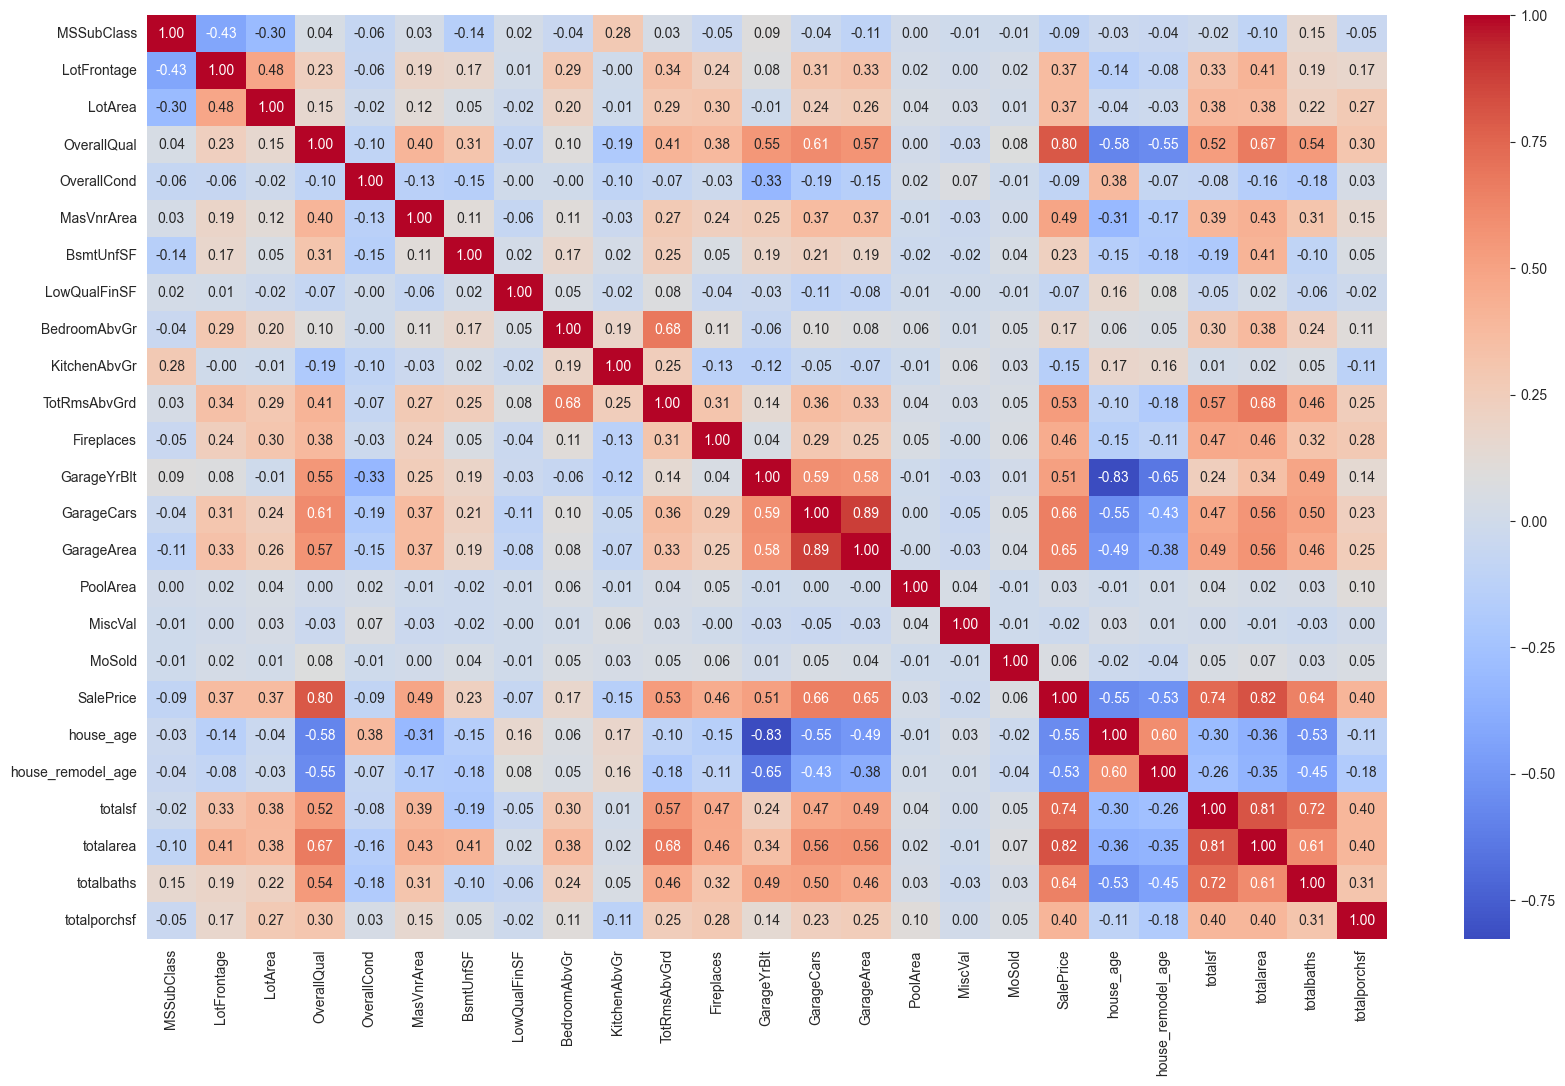

In [214]:
correlation_matrix = df_train.corr(numeric_only=True)
plt.figure(figsize=(20,12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")

In [215]:
df_train.drop(columns=['GarageArea'])
df_test.drop(columns=['GarageArea'])

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,MiscVal,MoSold,SaleType,SaleCondition,house_age,house_remodel_age,totalsf,totalarea,totalbaths,totalporchsf
0,20,RH,80.0,11622,Pave,No,Reg,Lvl,AllPub,Inside,...,0,6,WD,Normal,49,49,1508.0,1778.0,1.0,260
1,20,RL,81.0,14267,Pave,No,IR1,Lvl,AllPub,Corner,...,12500,6,WD,Normal,52,52,2252.0,2658.0,1.5,429
2,60,RL,74.0,13830,Pave,No,IR1,Lvl,AllPub,Inside,...,0,3,WD,Normal,13,12,2420.0,2557.0,2.5,246
3,60,RL,78.0,9978,Pave,No,IR1,Lvl,AllPub,Inside,...,0,6,WD,Normal,12,12,2206.0,2530.0,2.5,396
4,120,RL,43.0,5005,Pave,No,IR1,HLS,AllPub,Inside,...,0,1,WD,Normal,18,18,1543.0,2560.0,2.0,226
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1454,160,RM,21.0,1936,Pave,No,Reg,Lvl,AllPub,Inside,...,0,6,WD,Normal,36,36,1092.0,1638.0,1.5,0
1455,160,RM,21.0,1894,Pave,No,Reg,Lvl,AllPub,Inside,...,0,4,WD,Abnorml,36,36,1344.0,1638.0,1.5,24
1456,20,RL,160.0,20000,Pave,No,Reg,Lvl,AllPub,Inside,...,0,9,WD,Abnorml,46,10,2448.0,2448.0,2.0,474
1457,85,RL,62.0,10441,Pave,No,Reg,Lvl,AllPub,Inside,...,700,7,WD,Normal,14,14,1307.0,1882.0,1.5,112


<Axes: xlabel='SalePrice', ylabel='Count'>

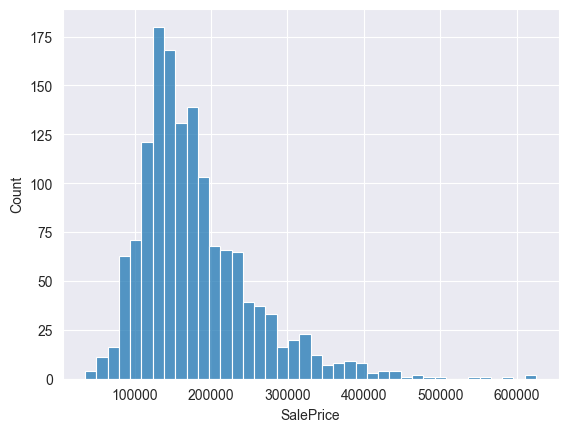

In [216]:
sns.histplot(df_train , x = df_train['SalePrice'])

In [217]:
df_train['SalePrice'] = np.log1p(df_train['SalePrice'])

<Axes: xlabel='SalePrice', ylabel='Count'>

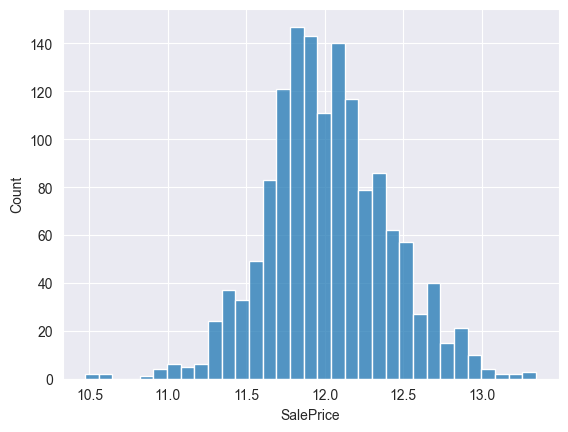

In [218]:
sns.histplot(df_train , x = df_train['SalePrice'])


In [219]:
df_train.dtypes[df_train.dtypes == 'object']
#df_train.dtypes[df_train.dtypes != 'object']

MSZoning         object
Street           object
Alley            object
LotShape         object
LandContour      object
Utilities        object
LotConfig        object
LandSlope        object
Neighborhood     object
Condition1       object
Condition2       object
BldgType         object
HouseStyle       object
RoofStyle        object
RoofMatl         object
Exterior1st      object
Exterior2nd      object
MasVnrType       object
ExterQual        object
ExterCond        object
Foundation       object
BsmtQual         object
BsmtCond         object
BsmtExposure     object
BsmtFinType1     object
BsmtFinType2     object
Heating          object
HeatingQC        object
CentralAir       object
Electrical       object
KitchenQual      object
Functional       object
FireplaceQu      object
GarageType       object
GarageFinish     object
GarageQual       object
GarageCond       object
PavedDrive       object
PoolQC           object
Fence            object
MiscFeature      object
SaleType        

In [220]:
ordinal_encoding_cols =['LotShape', 'LandContour','Utilities','LandSlope',  'BsmtQual',  'BsmtFinType1',  'CentralAir',  'Functional', \
           'FireplaceQu', 'GarageFinish', 'GarageQual', 'PavedDrive', 'ExterCond', 'KitchenQual', 'BsmtExposure', 'HeatingQC','ExterQual', 'BsmtCond']
one_hot_encoding_cols =['Street', 'LotConfig','Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'Exterior1st', 'Exterior2nd',
           'MasVnrType','Foundation',  'Electrical',  'SaleType', 'MSZoning', 'SaleCondition', 'Heating', 'GarageType', 'RoofMatl']

In [221]:
num_cols = df_train.select_dtypes(include=['int64', 'float64']).columns
num_cols = num_cols.drop('SalePrice')

In [222]:
num_pipeline = Pipeline(steps = [('impute', SimpleImputer(strategy = 'mean')),('scaler' , StandardScaler())])
ode_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('ode', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

In [223]:
ohe_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

In [224]:
col_trans = ColumnTransformer(transformers=[
    ('num_p', num_pipeline, num_cols),
    ('ode_p', ode_pipeline, ordinal_encoding_cols),
    ('ohe_p', ohe_pipeline, one_hot_encoding_cols),
], remainder='drop', n_jobs=-1)


In [225]:
pipeline = Pipeline(steps=[
    ('preprocessing', col_trans)
])

In [226]:
X = df_train.drop('SalePrice', axis=1)
y = df_train['SalePrice']

In [227]:
X_preprocessed = pipeline.fit_transform(X)


/opt/homebrew/Cellar/python@3.13/3.13.3/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/opt/homebrew/Cellar/python@3.13/3.13.3/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/opt/homebrew/Cellar/python@3.13/3.13.3/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See http

In [228]:
X_train, X_test, y_train, y_test = train_test_split(X_preprocessed, y, test_size=0.2, random_state=42)


# Build Models


In [229]:
print(X_preprocessed[:5])  # check for any str value


[[ 0.07887505 -0.2169492  -0.28610364  0.67283452 -0.52431712  0.53085704
  -0.94519351 -0.11278022  0.17225441 -0.21613565  0.94504791 -0.95065674
   1.02216808  0.32058101  0.37066411 -0.05234055 -0.08598973 -1.6075071
  -1.04334766 -0.87228819  0.63031355  0.02234648  1.69194562 -0.76917154
   3.          3.          0.          0.          2.          2.
   1.          6.          2.          1.          4.          2.
   4.          2.          3.          0.          2.          3.
   0.          1.          0.          0.          0.          0.
   1.          0.          0.          0.          0.          0.
   1.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          1.          0.
   0.          0.          0.          0.          0.          0.
   0.          1.          0.          0.    

In [230]:
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [231]:
y_pred_lr = model.predict(X_test)

In [232]:
mean_squared_error(y_test, y_pred_lr)

0.0173559002460372

In [233]:
RFR = RandomForestRegressor(random_state=42)
param_grid_RFR = {
    'max_depth': [5, 10, 15],
    'n_estimators': [100, 250, 500],
    'min_samples_split': [3, 5, 10]
}

In [234]:
rfr_cv = GridSearchCV(RFR, param_grid_RFR, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)


In [235]:
rfr_cv.fit(X_train, y_train)


/opt/homebrew/Cellar/python@3.13/3.13.3/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/opt/homebrew/Cellar/python@3.13/3.13.3/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/opt/homebrew/Cellar/python@3.13/3.13.3/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See http

,estimator,RandomForestR...ndom_state=42)
,param_grid,"{'max_depth': [5, 10, ...], 'min_samples_split': [3, 5, ...], 'n_estimators': [100, 250, ...]}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,500


In [236]:
np.sqrt(-1 * rfr_cv.best_score_)


np.float64(0.13305729553826)

In [237]:
rfr_cv.best_params_



{'max_depth': 15, 'min_samples_split': 3, 'n_estimators': 500}

In [238]:
XGB = XGBRegressor(random_state=13)
param_grid_XGB = {
    'learning_rate': [0.05, 0.1, 0.2],
    'n_estimators': [300],
    'max_depth': [3],
    'min_child_weight': [1,2,3],
    'gamma': [0, 0.1, 0.2],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0],
}

In [239]:
xgb_cv = GridSearchCV(XGB, param_grid_XGB, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)


In [240]:
xgb_cv.fit(X_train, y_train)


,estimator,"XGBRegressor(...ree=None, ...)"
,param_grid,"{'colsample_bytree': [0.8, 0.9, ...], 'gamma': [0, 0.1, ...], 'learning_rate': [0.05, 0.1, ...], 'max_depth': [3], ...}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'reg:squarederror'


In [241]:
np.sqrt(-1 * xgb_cv.best_score_)


np.float64(0.11462714559316343)

In [164]:
ridge = Ridge()
param_grid_ridge = {
    'alpha': [0.05, 0.1, 1, 3, 5, 10],
    'solver': ['auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag']
}

ridge_cv = GridSearchCV(ridge, param_grid_ridge, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
ridge_cv.fit(X_train, y_train)



/Users/birhatmf/Documents/house-prices-advanced-regression-techniques/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/birhatmf/Documents/house-prices-advanced-regression-techniques/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/birhatmf/Documents/house-prices-advanced-regression-techniques/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/birhatmf/Documents/house-prices-advanced-regression-techniques/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,estimator,Ridge()
,param_grid,"{'alpha': [0.05, 0.1, ...], 'solver': ['auto', 'svd', ...]}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,10


In [166]:
np.sqrt(-1 * ridge_cv.best_score_)


np.float64(0.12456449596311213)

In [167]:
from sklearn.ensemble import GradientBoostingRegressor

GBR = GradientBoostingRegressor()


In [168]:
param_grid_GBR = {
    'max_depth': [12, 15, 20],
    'n_estimators': [200, 300, 1000],
    'min_samples_leaf': [10, 25, 50],
    'learning_rate': [0.001, 0.01, 0.1],
    'max_features': [0.01, 0.1, 0.7]}
GBR_cv = GridSearchCV(GBR, param_grid_GBR, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
GBR_cv.fit(X_train, y_train)



,estimator,GradientBoostingRegressor()
,param_grid,"{'learning_rate': [0.001, 0.01, ...], 'max_depth': [12, 15, ...], 'max_features': [0.01, 0.1, ...], 'min_samples_leaf': [10, 25, ...], ...}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'squared_error'


In [169]:
np.sqrt(-1 * GBR_cv.best_score_)


np.float64(0.11866917469367634)

In [175]:
#np.sqrt(-1 * lgbm_cv.best_score_)
#np.float64(0.12802369652256373)


In [176]:
catboost = CatBoostRegressor(loss_function='RMSE', verbose=False)
param_grid_cat ={
    'iterations': [100, 500, 1000],
    'depth': [4, 6, 8, 10],
    'learning_rate': [0.01, 0.05, 0.1, 0.5]
}
cat_cv = GridSearchCV(catboost, param_grid_cat, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
cat_cv.fit(X_train, y_train)


,estimator,<catboost.cor...t 0x12c07f4d0>
,param_grid,"{'depth': [4, 6, ...], 'iterations': [100, 500, ...], 'learning_rate': [0.01, 0.05, ...]}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False


In [179]:
np.sqrt(-1 * cat_cv.best_score_)



np.float64(0.11851526234631832)

In [181]:
from sklearn.ensemble import VotingRegressor

vr = VotingRegressor([('gbr', GBR_cv.best_estimator_),
                      ('xgb', xgb_cv.best_estimator_),
                      ('ridge', ridge_cv.best_estimator_)],
                    weights=[2,3,1])
vr.fit(X_train, y_train)
y_pred_vr = vr.predict(X_test)
mean_squared_error(y_test, y_pred_vr)




0.01861378041286675

In [183]:
estimators = [
    ('gbr', GBR_cv.best_estimator_),
    ('xgb', xgb_cv.best_estimator_),
    ('cat', cat_cv.best_estimator_),
    ('rfr', rfr_cv.best_estimator_),
]

In [184]:
from sklearn.ensemble import StackingRegressor

stackreg = StackingRegressor(
            estimators = estimators,
            final_estimator = vr
)
stackreg.fit(X_train, y_train)
y_pred_stack = stackreg.predict(X_test)


In [186]:
mean_squared_error(y_test, y_pred_stack)

0.019872690085518223